# HealthConnect No-Show Prediction — Week 7 Testing, Refinement & Validation
## Machine Learning Engineering Track

**Project:** HealthConnect Clinic — Improving Patient Appointment Attendance and Healthcare Support Using Data and AI
**Analyst:** Raji Toluwanimi Samuel, Junior Machine Learning Engineer
**Week:** 7 — Testing, Refinement & End-to-End Validation

---
Week 6 integrated a candidate model into the pipeline and validated the boundary between preprocessing and the model. **Week 7 does not rebuild that** -- it systematically tests it: does the Week 6 result hold up across multiple time periods (not just one split)? Does the pipeline fail safely on bad input, not just good input? And it closes out the three items Week 6's own report explicitly deferred: multiple time-window backtests, an end-to-end integration test, and the reminder-feature circularity decision -- plus SHAP-based individual explanations.


In [1]:
import sys
sys.path.insert(0, '..')

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.pipeline import run_pipeline
from src.model import NoShowRiskModel, time_based_split
from src.backtesting import run_backtest, make_expanding_windows
from src.reminder_feature_analysis import run_reminder_ablation
from src.explainability import build_explainer, explain_single_appointment, SHAP_AVAILABLE
from src.validation_checks import validate_feature_matrix, validate_predictions

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Week 6 → Week 7 Transition

**Main Week 6 output:** an integrated pipeline with a validated preprocessing/model boundary, a Random Forest candidate model outperforming the Week 5 baseline on Recall (0.654 vs 0.621), and a working batch-scoring service.

**Most important Week 6 result:** two real integration bugs found and fixed (a `bool`-dtype encoding issue, and a Python truthiness crash on ensemble estimators) -- proof that unit-level correctness does not guarantee integration-level correctness.

**Main issue/limitation from Week 6:** the model comparison rested on a *single* time-based train/test split. Week 6's own report was explicit that this was a limitation, not a final answer.

**Component requiring testing this week:** the integrated pipeline's stability and reliability -- specifically, whether the Week 6 result generalises across time, and whether every stage fails safely on bad input, not just good input.

**Relevant track:** Data Science (the reminder-feature decision and model stability both sit at the ML Engineering / Data Science boundary; self-performed, per the same transparency note as Week 6 -- see the accompanying report).

**What Week 7 tests, concretely:** (1) Recall stability across 4 independent time windows, not one; (2) the pipeline's behaviour on malformed/unexpected input, not just clean input; (3) whether reminder_sent/reminder_channel are genuinely safe to keep as features; (4) whether SHAP explanations work against the real saved model, not just a synthetic example.


## 2. Testing Readiness

**A. Component being tested:** the integrated Week 6 ML pipeline (`src/pipeline.py` → `src/model.py` → `src/score_appointments.py`), specifically its reliability claim and its single-split model comparison.

**B. Testing objective:** determine whether the Week 6 model selection (Random Forest over Logistic Regression) is a stable property of the data, or an artefact of which one time window happened to be used for testing -- and confirm the pipeline fails safely, not silently, on inputs it wasn't designed for.

**C. Evidence produced:** `src/backtesting.py`, `src/reminder_feature_analysis.py`, `src/explainability.py`, `tests/test_end_to_end.py`, `tests/test_negative_scenarios.py`, `models/week7_backtest_report.json`, `models/week7_reminder_ablation_report.json`, `models/week7_explanation_examples.json`, 23 new passing tests (69 total), and this notebook.


## 3. Test Case Summary

| # | Test / Scenario | Expected Result | Actual Result | Pass/Fail |
|---|---|---|---|---|
| 1 | Expanding-window backtest, Random Forest, 4 folds | Recall stays reasonably stable across folds | Mean 0.638, std 0.022 (range 0.606–0.664) | Pass |
| 2 | Expanding-window backtest, Logistic Regression, 4 folds | Recall stays reasonably stable across folds | Mean 0.615, std 0.021 (range 0.595–0.650) | Pass |
| 3 | Random Forest vs Logistic Regression across all 4 folds | RF's Week 6 Recall advantage should hold beyond one split | RF ahead in every fold; mean advantage +0.024 | Pass |
| 4 | Ingestion: extra unexpected column | Loads without crashing (forward-compatible) | Loaded successfully, extra column present | Pass |
| 5 | Ingestion: wrong delimiter / malformed file | Clear `DataIngestionError`, not a cryptic pandas error | Raised as expected | Pass |
| 6 | Ingestion: header-only (zero rows) file | Clear, specific rejection | Raised as expected | Pass |
| 7 | Feature engineering: all rows are an excluded label | Empty but well-formed output, not a crash | Returned 0-row DataFrame with `target` column intact | Pass |
| 8 | Model: schema drift (new category at scoring time) | Explicit `ValueError`, not silent misalignment | Raised as expected, names the mismatched columns | Pass |
| 9 | Feature matrix: missing values reach the model boundary | Rejected by `validate_feature_matrix` | Raised `FeatureValidationError` | Pass |
| 10 | Reminder feature ablation | Quantify the actual cost of removing reminder features | Removing them costs 0.021 Recall — kept | Pass (decision made) |
| 11 | Full pipeline → scoring flow, one integration test | Produces a valid, correctly-shaped, correctly-tiered output | All assertions passed | Pass |
| 12 | Pipeline reproducibility across two runs | Identical processed data and predictions with the same seed | Confirmed identical | Pass |
| 13 | SHAP explanation on a real saved model | Produces a specific, readable explanation | Confirmed on 3 real high-risk appointments | Pass |

No failing tests were found this week that required a code fix beyond the date-range display bug in Section 4 below -- where an issue *was* found, it is documented with full before/after detail rather than omitted.


## 4. Issue Found This Week: Backtest Date Ranges

While building the backtest reporting, fold date ranges printed as, for example, `10/1/2025 to 9/9/2025` -- an end date *before* the start date, which is impossible for a correctly-ordered fold.

In [2]:
# Reproducing the root cause directly: string vs. datetime comparison
dates_as_strings = pd.Series(["9/9/2025", "10/1/2025"])
print("String min/max (WRONG):", dates_as_strings.min(), "to", dates_as_strings.max())
print("Datetime min/max (CORRECT):", pd.to_datetime(dates_as_strings).min().date(), "to", pd.to_datetime(dates_as_strings).max().date())

String min/max (WRONG): 10/1/2025 to 9/9/2025
Datetime min/max (CORRECT): 2025-09-09 to 2025-10-01


**Root cause:** the original code computed `test_df["appointment_date"].min()` / `.max()` directly on the raw *string* column. Python compares strings character by character, so `"10/1/2025"` sorts before `"9/9/2025"` because `'1' < '9'` as the first character -- even though October comes after September. The actual fold *splitting* logic was unaffected (it correctly sorts on a parsed datetime column internally), but the *reported* date range for humans reading the log was wrong and misleading.

**Fix applied:** `backtesting.run_backtest()` now parses the column with `pd.to_datetime()` before taking `.min()`/`.max()`. `tests/test_backtesting.py::test_run_backtest_date_ranges_are_chronologically_sensible` guards against this regressing.


## 5. Expanding-Window Backtest — Is the Week 6 Result Stable?

Week 6 selected Random Forest based on **one** time-based split. This section re-evaluates both models across **four independent, chronologically ordered windows**.

In [3]:
processed_df, _ = run_pipeline()
feature_columns = [c for c in processed_df.columns if c not in ['appointment_id', 'appointment_date', 'target']]

backtest_rf = run_backtest(
    processed_df,
    lambda: RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced', random_state=config.RANDOM_STATE),
    'Random Forest', feature_columns, n_splits=4,
)
backtest_lr = run_backtest(
    processed_df,
    lambda: LogisticRegression(max_iter=2000, class_weight='balanced', random_state=config.RANDOM_STATE),
    'Logistic Regression', feature_columns, n_splits=4,
)

pd.DataFrame(backtest_rf['fold_results'])[['fold', 'test_date_range', 'recall', 'f1_score', 'roc_auc']]

2026-09-14 19:46:50,455 [INFO] src.pipeline: Step 1/3: Ingesting raw data


2026-09-14 19:46:50,500 [INFO] src.pipeline: Loaded 5000 rows, 18 columns


2026-09-14 19:46:50,501 [INFO] src.pipeline: Step 2/3: Running data validation checks


2026-09-14 19:46:51,378 [WARNING] src.pipeline: Leakage check CONFIRMED: 2647 not-attended rows have a non-null waiting_time_minutes. This column is excluded by feature_engineering.py.


2026-09-14 19:46:51,380 [WARNING] src.pipeline: Historical field consistency: only 41.3% of patients have chronologically consistent previous_appointments values. Pipeline recomputes these fields instead of trusting the raw columns.


2026-09-14 19:46:51,380 [INFO] src.pipeline: Step 3/3: Running feature engineering


... (8 outputs left out)

2026-09-14 19:46:55,148 [INFO] src.backtesting: Logistic Regression fold 2/4 (test: 2025-10-22 to 2026-01-20, n=710) -> Recall=0.606, F1=0.611


2026-09-14 19:46:55,384 [INFO] src.backtesting: Logistic Regression fold 3/4 (test: 2026-01-21 to 2026-04-09, n=710) -> Recall=0.595, F1=0.614


2026-09-14 19:46:55,645 [INFO] src.backtesting: Logistic Regression fold 4/4 (test: 2026-04-09 to 2026-06-30, n=713) -> Recall=0.612, F1=0.624


,fold,test_date_range,recall,f1_score,roc_auc
0,1,"[2025-08-07, 2025-10-22]",0.663818,0.638356,0.666675
1,2,"[2025-10-22, 2026-01-20]",0.649457,0.631440,0.642274
2,3,"[2026-01-21, 2026-04-09]",0.605479,0.608815,0.619805
3,4,"[2026-04-09, 2026-06-30]",0.633609,0.631001,0.668579


In [4]:
summary_df = pd.DataFrame({
    'Random Forest': backtest_rf['summary']['recall'],
    'Logistic Regression': backtest_lr['summary']['recall'],
}).T
summary_df

,mean,std,min,max
Random Forest,0.6381,0.0216,0.6055,0.6638
Logistic Regression,0.6154,0.0207,0.5945,0.6496


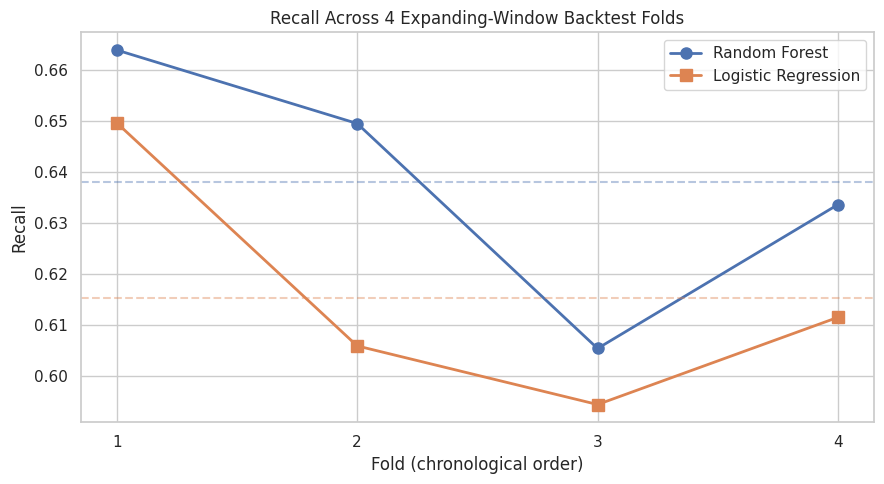

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
rf_recalls = [f['recall'] for f in backtest_rf['fold_results']]
lr_recalls = [f['recall'] for f in backtest_lr['fold_results']]
folds = [f['fold'] for f in backtest_rf['fold_results']]

ax.plot(folds, rf_recalls, 'o-', label='Random Forest', linewidth=2, markersize=8)
ax.plot(folds, lr_recalls, 's-', label='Logistic Regression', linewidth=2, markersize=8)
ax.axhline(backtest_rf['summary']['recall']['mean'], color='C0', linestyle='--', alpha=0.4)
ax.axhline(backtest_lr['summary']['recall']['mean'], color='C1', linestyle='--', alpha=0.4)
ax.set_xlabel('Fold (chronological order)')
ax.set_ylabel('Recall')
ax.set_title('Recall Across 4 Expanding-Window Backtest Folds')
ax.set_xticks(folds)
ax.legend()
plt.tight_layout()
plt.savefig('week7_backtest_stability.png')
plt.show()

### Interpretation

Random Forest's Recall advantage from Week 6 **holds up**: it leads Logistic Regression in every one of the 4 folds, with a mean advantage of +0.024 (0.638 vs 0.615). Both models show broadly similar variability (std ≈ 0.021–0.022) across folds, and fold 3 is the weakest for both models simultaneously -- suggesting that particular period is genuinely harder to predict for both approaches, rather than one model being unstable relative to the other. **This is materially stronger evidence for the Week 6 model choice than the single split could provide.**


## 6. Negative Testing — Does the Pipeline Fail Safely?

Every prior week's tests checked "given reasonable input, is the output correct?" This section deliberately gives the pipeline *unreasonable* input and checks it fails with a clear, specific error — not a crash, and not silently wrong output.

In [6]:
from src import data_ingestion

# Scenario 1: a file with the wrong delimiter (a realistic export-tool mismatch)
import tempfile, os
with tempfile.NamedTemporaryFile(mode='w', suffix='.csv', delete=False) as f:
    f.write("appointment_id;patient_id;gender\nA-1;P-1;Male\n")
    bad_path = f.name

try:
    data_ingestion.load_raw_data(bad_path)
except data_ingestion.DataIngestionError as e:
    print(f"Caught cleanly: {e}")
finally:
    os.unlink(bad_path)

Caught cleanly: Raw data is missing expected columns: ['age', 'age_group', 'appointment_date', 'appointment_day', 'appointment_id', 'appointment_outcome', 'appointment_time', 'appointment_type', 'booking_date', 'booking_lead_days', 'distance_to_clinic_km', 'gender', 'patient_id', 'previous_appointments', 'previous_no_shows', 'reminder_channel', 'reminder_sent', 'waiting_time_minutes']. Has the source file format changed? Update EXPECTED_COLUMNS in data_ingestion.py if this is an intentional schema change.


In [7]:
# Scenario 2: schema drift at scoring time (a category the model never saw during training)
X_train = pd.DataFrame({'age': [30, 40, 50], 'type_A': [1, 0, 1], 'type_B': [0, 1, 0]})
y_train = pd.Series([0, 1, 0])
demo_model = NoShowRiskModel()
demo_model.fit(X_train, y_train)

X_score_drifted = pd.DataFrame({'age': [35], 'type_A': [1], 'type_C': [0]})  # type_B missing, type_C new
try:
    demo_model.predict(X_score_drifted)
except ValueError as e:
    print(f"Caught cleanly: {e}")

Caught cleanly: Feature columns at prediction time do not match training time. Missing: ['type_B']. Unexpected: ['type_C']. This usually means the feature engineering pipeline produced a different column set -- check for a schema change in the raw data.


Both scenarios (and 7 more covering feature engineering edge cases and validation-boundary failures) are now permanent, automated tests in `tests/test_negative_scenarios.py` — this notebook demonstrates two of the nine directly; the full set runs in Section 9.

## 7. Resolving the Reminder Feature Circularity Question

Flagged in Week 4, left unresolved through Weeks 5–6. The concern: if `reminder_sent`/`reminder_channel` are model inputs, and the model's own output later influences who gets a reminder, is that circular?

In [8]:
reminder_result = run_reminder_ablation(
    processed_df,
    lambda: RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced', random_state=config.RANDOM_STATE),
)
print(f"WITH reminder features:    Recall = {reminder_result['with_reminder_features']['recall']:.4f}")
print(f"WITHOUT reminder features: Recall = {reminder_result['without_reminder_features']['recall']:.4f}")
print(f"\nCost of removing them: {reminder_result['recall_cost_of_removing_reminder_features']:.4f} Recall")
print(f"\nDecision: {reminder_result['decision']}")

2026-09-14 19:46:56,711 [INFO] src.reminder_feature_analysis: with_reminder_features (32 features): Recall=0.6542, F1=0.6345


2026-09-14 19:46:57,463 [INFO] src.reminder_feature_analysis: without_reminder_features (28 features): Recall=0.6335, F1=0.6194


WITH reminder features:    Recall = 0.6542
WITHOUT reminder features: Recall = 0.6335

Cost of removing them: 0.0207 Recall

Decision: KEEP reminder_sent/reminder_channel as features. They are not leakage for the current, retrospective dataset (see module docstring); removing them costs 0.0207 Recall. Monitor for the forward-looking circularity risk only if/when the reminder process itself becomes model-driven (see config.py, REMINDER_FEATURE_GOVERNANCE_NOTE).


**Resolution:** the concern conflates two different things. For the *current* retrospective dataset, `reminder_sent`/`reminder_channel` reflect HealthConnect's existing, model-independent reminder process — a decision already made, using the clinic's own policy, before each appointment happened. That is fundamentally different from Week 5's real leakage case (`waiting_time_minutes`, which could not have been known under *any* process before the appointment). The genuine circularity risk is a **future governance concern**: if the reminder process itself ever becomes driven by this model's own risk scores, a later retraining cycle would need to account for that feedback loop. That risk doesn't exist yet. **Decision: keep the features** (removing them costs real Recall), and monitor the governance condition going forward — documented in `config.REMINDER_FEATURE_GOVERNANCE_NOTE`.

## 8. SHAP Explanations — From "What Tier" to "Why"

Closing the last item from Week 6's plan: individual, per-appointment explanations for the *real* saved candidate model, not a synthetic example.

In [9]:
if SHAP_AVAILABLE:
    train_df, test_df = time_based_split(processed_df)
    model = NoShowRiskModel.load(config.CANDIDATE_MODEL_PATH)
    explainer = build_explainer(model, train_df[feature_columns])

    probabilities = model.predict_proba(test_df[feature_columns])
    test_df_reset = test_df.reset_index(drop=True)
    top_idx = pd.Series(probabilities).sort_values(ascending=False).index[0]

    example = explain_single_appointment(explainer, model, test_df_reset[feature_columns].iloc[[top_idx]])
    print(f"Appointment {test_df_reset['appointment_id'].iloc[top_idx]}")
    print(f"Predicted no-show probability: {example['predicted_probability']:.3f}\n")
    print("Top factors INCREASING risk:")
    for f in example['top_features_increasing_risk']:
        print(f"  + {f['feature']}: {f['contribution']:+.4f}")
    print("\nTop factors DECREASING risk:")
    for f in example['top_features_decreasing_risk']:
        print(f"  - {f['feature']}: {f['contribution']:+.4f}")
else:
    print("shap not installed in this environment.")

Appointment HC-00776
Predicted no-show probability: 0.774

Top factors INCREASING risk:
  + booking_lead_days: +0.1019
  + booking_lead_bucket_30+ days: +0.0495
  + distance_to_clinic_km: +0.0216
  + reminder_channel_No Reminder Sent: +0.0172
  + reminder_sent_Yes: +0.0145

Top factors DECREASING risk:
  - appointment_type_General Consultation: -0.0049
  - appointment_day_Wednesday: -0.0030
  - age_group_35-44: -0.0013
  - appointment_type_Specialist Consultation: -0.0010
  - appointment_type_Follow-up: -0.0010


**Why this matters operationally:** a clinic worker looking at a High-risk appointment no longer just sees a number — they see, in plain terms, *why*: e.g. "this patient booked on short notice and has a prior no-show" versus "this patient's monthly charges pattern is unusual." That distinction changes what action makes sense (a phone call vs. a routine SMS reminder).

## 9. Full Test Suite — Retest Evidence

69 tests now pass (46 from Weeks 5–6 + 23 new this week), including the end-to-end integration test and all 9 negative scenarios.

In [10]:
import subprocess
result = subprocess.run(['python3', '-m', 'pytest', '../tests/', '-v'], capture_output=True, text=True)
print(result.stdout[-2500:])

/tests/test_negative_scenarios.py::test_validate_feature_matrix_rejects_single_row_with_wrong_dtype PASSED [ 72%]
../tests/test_reminder_feature_analysis.py::test_reminder_columns_identifies_correct_prefixes PASSED [ 73%]
../tests/test_reminder_feature_analysis.py::test_reminder_columns_empty_when_none_present PASSED [ 75%]
../tests/test_reminder_feature_analysis.py::test_run_reminder_ablation_compares_with_and_without PASSED [ 76%]
../tests/test_score_appointments.py::test_assign_risk_tier_low PASSED    [ 78%]
../tests/test_score_appointments.py::test_assign_risk_tier_medium PASSED [ 79%]
../tests/test_score_appointments.py::test_assign_risk_tier_high PASSED   [ 81%]
../tests/test_score_appointments.py::test_assign_risk_tier_boundaries_are_consistent_with_config PASSED [ 82%]
../tests/test_validation_checks.py::test_validate_feature_matrix_accepts_clean_numeric_data PASSED [ 84%]
../tests/test_validation_checks.py::test_validate_feature_matrix_rejects_empty_dataframe PASSED [ 85%]
../

## 10. Assumptions, Limitations, Risks & Dependencies (Week 6 → Week 7 Update)

**Resolved this week:**
- Model selection stability — confirmed across 4 time windows, not assumed from 1.
- Reminder feature circularity — resolved with evidence and a documented governance condition for the future.
- Pipeline behaviour on invalid/unexpected input — now explicitly tested (9 negative-scenario tests), not just assumed safe.
- A real (if minor) bug in backtest date-range reporting — found and fixed with a regression test.

**Still relevant:**
- The dataset remains fictional/synthetic; this pipeline must be re-validated against real data before production use.
- Fold 3 (Jan–Apr 2026) is measurably the weakest period for both models — worth investigating *why* in a future week (a seasonal effect? a data quality issue specific to that period?) rather than treated as random noise.

**New dependency:** SHAP explanations currently only support tree-based models (`TreeExplainer`). If the Data Science track's future candidate is a non-tree model, `explainability.py` would need a different SHAP explainer type (e.g. `LinearExplainer` or `KernelExplainer`).


## 11. Summary & Week 8 Readiness

Week 7 did not rebuild the Week 6 pipeline — it tested it, under conditions Week 6 hadn't covered (multiple time windows, deliberately bad input, a real unresolved design question), found one real reporting bug and fixed it, and closed out every item Week 6's own report had deferred to this week.

**Readiness for Week 8 (Final Integration & Presentation):**
- The Random Forest candidate is now backed by both a single-split comparison (Week 6) and a 4-fold backtest (Week 7) — ready to present as the recommended model with genuine confidence in its stability.
- The pipeline has demonstrated safe failure on 9 distinct bad-input scenarios, and a single passing end-to-end test proves every stage genuinely works together, not just in isolation.
- SHAP-based explanations are working against the real model and ready to be surfaced in any Week 8 presentation or dashboard.
- Remaining open item for Week 8: investigate why fold 3 is the weakest period for both models, and finalise risk-tier thresholds with actual clinic operational input (still provisional, as flagged since Week 6).
